# Red Densa


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


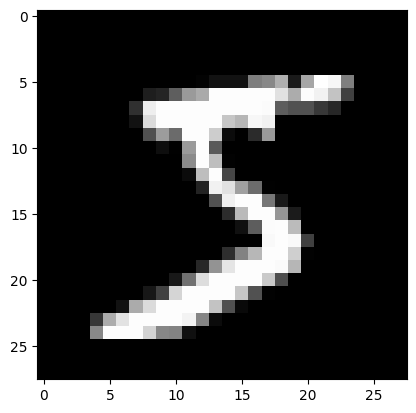

In [ ]:
import numpy as np
import tensorflow as tf

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.reshape(x_train.shape[0], 28 * 28)
x_test = x_test.reshape(x_test.shape[0], 28 * 28)

import matplotlib.pyplot as plt

plt.imshow(x_train[0].reshape(28, 28), cmap='gray')

In [ ]:
#MODELO FUNCIONAL  NO SECUENCIAL
#S
In=tf.keras.layers.Input(shape=(784,))
Cp1=tf.keras.layers.Dense(64,activation='relu')(In)
Cp2=tf.keras.layers.Dense(64,activation='relu')(Cp1)
Out=tf.keras.layers.Dense(10,activation='softmax')(Cp2)
Model = tf.keras.Model(inputs=In, outputs=Out)



Model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
Model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
Model.fit(x_train, y_train, epochs=30, batch_size=32)

Epoch 1/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8343 - loss: 1.7923
Epoch 2/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9069 - loss: 0.3914
Epoch 3/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9229 - loss: 0.3167
Epoch 4/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9344 - loss: 0.2677
Epoch 5/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9443 - loss: 0.2244
Epoch 6/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9520 - loss: 0.1858
Epoch 7/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9564 - loss: 0.1626
Epoch 8/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9603 - loss: 0.1458
Epoch 9/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9638 - loss: 0.1315
Epoch 10/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9671 - loss: 0.1180
Epoch 11/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9675 - loss: 0.1131
Epoch 12/30
1875/1875 ━━━━━━━━

In [ ]:
Model.save("mnist_model.keras")

In [ ]:
from google.colab import files
files.download("mnist_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Convolucional

In [2]:
import numpy as np
import tensorflow as tf

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
#x_train = x_train.reshape(x_train.shape[0], 28 * 28)
#x_test = x_test.reshape(x_test.shape[0], 28 * 28)

#import matplotlib.pyplot as plt

#plt.imshow(x_train[0].reshape(28, 28), cmap='gray')

# Agrega una dimesnsion filas, ancho, alto, canales (e.g. from (60000, 28, 28) to (60000, 28, 28, 1))
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("x_train shape:", x_train.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train shape: (60000, 28, 28, 1)


In [3]:
#MODELO FUNCIONAL  NO SECUENCIAL

In=tf.keras.layers.Input(shape=(28,28,1), name = "input") # ingnorar las filas
#convolucionales
conv1 = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', strides = 1, padding = "same", name = "conv1")(In)

# maxpooling 2x2
max=tf.keras.layers.MaxPooling2D((2,2), name = "maxP1")(conv1)

conv2 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', strides = 1, padding = "same", name = "conv2")(max)

#maxpooling2 2x2
max2 = tf.keras.layers.MaxPooling2D((2,2), name = "maxP2")(conv2)

# aplanar
f = tf.keras.layers.Flatten(name = "Flatten")(max2)

# desas solo apra salida
Out=tf.keras.layers.Dense(10,activation='softmax', name = "Densa")(f)
Model = tf.keras.Model(inputs=In, outputs=Out)


In [4]:

Model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxP1 (MaxPooling2D)            │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxP2 (MaxPooling2D)            │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Densa (Dense)                   │ (None, 10)             │        31,370 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,186 (196.04 KB)

 Trainable params: 50,186 (196.04 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
Model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
Model.fit(x_train, y_train, epochs=30, batch_size=32, validation_split = 0.2)

Epoch 1/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/step - accuracy: 0.9429 - loss: 0.3573 - val_accuracy: 0.9787 - val_loss: 0.0752
Epoch 2/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.9793 - loss: 0.0705 - val_accuracy: 0.9773 - val_loss: 0.0815
Epoch 3/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9835 - loss: 0.0524 - val_accuracy: 0.9791 - val_loss: 0.0694
Epoch 4/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9862 - loss: 0.0433 - val_accuracy: 0.9847 - val_loss: 0.0616
Epoch 5/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9879 - loss: 0.0399 - val_accuracy: 0.9827 - val_loss: 0.0634
Epoch 6/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9886 - loss: 0.0360 - val_accuracy: 0.9834 - val_loss: 0.0651
Epoch 7/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9911 - loss: 0.0303 - val_accuracy: 0.9859 - val_loss: 0.0629
Epoch 8/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9913 - loss: 0.0293 

In [ ]:
#Model.save("mnist_model_conv.keras")

In [ ]:
#from google.colab import files
#files.download("mnist_model_conv.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

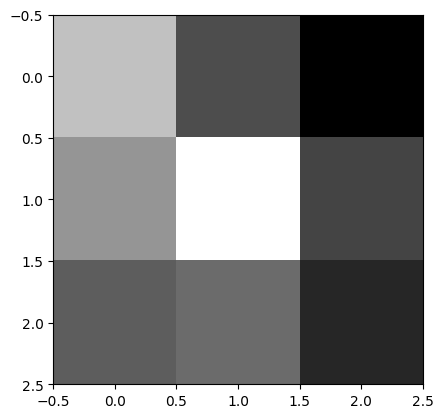

In [6]:
wc1 = Model.get_layer("conv1").get_weights()[0]
import matplotlib.pyplot as plt
plt.imshow(wc1[:,:,0,0], cmap='gray')

In [7]:
model_conv1 = tf.keras.Model(inputs = Model.input, outputs = Model.layers[1].output)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 541ms/step


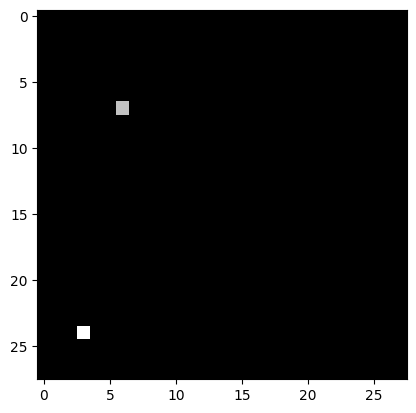

In [8]:
y_conv1 = model_conv1.predict(x_train[0].reshape(1,28,28,1))
plt.imshow(y_conv1[0,:,:,15], cmap='gray')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step


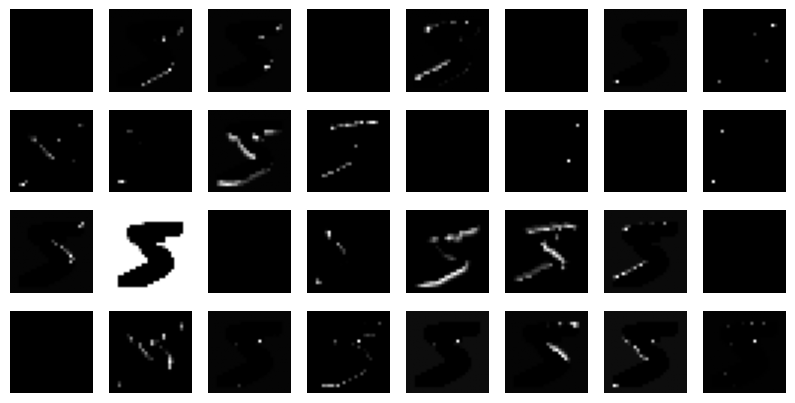

In [10]:
model_conv1 = tf.keras.Model( inputs=Model.input, outputs=Model.get_layer("conv1").output)
y_conv1 = model_conv1.predict(x_train[0].reshape(1, 28, 28, 1))

plt.figure(figsize=(10, 5))
for i in range(32):
      plt.subplot(4, 8, i + 1)
      plt.imshow(y_conv1[0, :, :, i], cmap="gray")
      plt.axis("off")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step


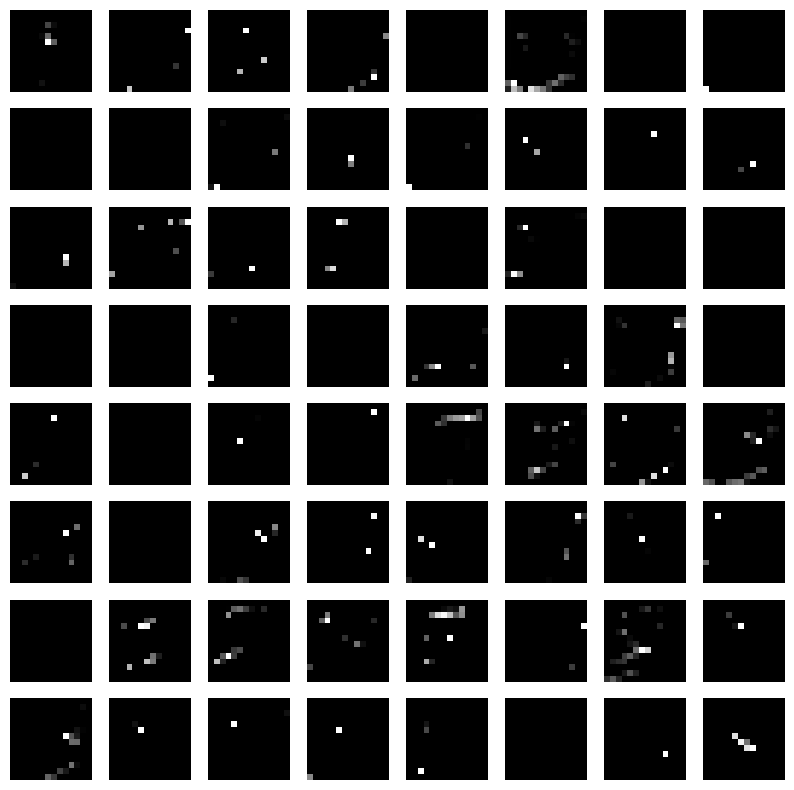

In [12]:
model_conv2 = tf.keras.Model( inputs=Model.input, outputs=Model.get_layer("conv2").output)
y_conv2 = model_conv2.predict(x_train[0].reshape(1, 28, 28, 1))

plt.figure(figsize=(10, 10))
for i in range(64):
      plt.subplot(8, 8, i + 1)
      plt.imshow(y_conv2[0, :, :, i], cmap="gray")
      plt.axis("off")
plt.show()


# Series de Tiempo


In [ ]:
dado mi modelo entrenado "Model" quiero un submodelo, que tenga la misma entrada y que su salida sea la priemra capa convolucion, con eso necesito 2 cosas una imagen del test y mirar la salida de esa capa o de ese modelo, y en una variable guardar la matriz de los filtros o kernels

SyntaxError: invalid syntax (567628089.py, line 1)